# group members:
- Savina Palihakkara  B01017193
- Yanrui Wang B01021602
- Weili Wang B00960200

# CSCI 3151 — Foundations of Machine Learning
### M19 — Feature Maps & the Kernel Trick

In this mini-lab, you'll work with a small synthetic dataset (two interleaving half-moons) and a classic handwritten digits dataset to explore how **kernel methods** extend linear models to learn nonlinear decision boundaries. You'll compare linear and kernelized SVMs, and see how hyperparameters like **C** and **gamma** shape both performance and decision boundaries. The stakeholders you should keep in mind are downstream users of a classifier (e.g., in a screening or triage system) who care about both **accuracy** and **reliability**.

**This mini-lab reinforces…**

- Thinking in terms of **feature maps** and **kernels** rather than just raw coordinates.
- Comparing **linear** vs **RBF-kernel** SVM decision boundaries on the same data.
- Reasoning about how **C** and **gamma** affect underfitting vs overfitting.
- Practicing **basic model evaluation** (train/validation/test splits & accuracy) for kernel methods.


## Assumptions & Scope

- You are comfortable with **Python**, **NumPy**, **pandas**, and basic plotting with **matplotlib**.  
- You have seen the ideas of **linear models**, **logistic regression**, and **support vector machines (SVMs)** in the video for M19.  
- We use small, clean datasets (a synthetic 2D toy example and the scikit-learn digits dataset) so that we can focus on the **geometry** of kernels rather than data wrangling.  
- We will **not** derive the full mathematical conditions for a valid kernel (positive semi-definiteness, Mercer’s theorem) in this notebook; instead, we will work with standard kernels from scikit-learn (`linear`, `poly`, `rbf`).  
- Time is limited (~30 minutes), so the core tasks focus on **running and interpreting experiments**, while the digits section is mostly a **stretch task** for faster groups.  


In [15]:
# Setup: imports and global configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Reproducibility
SEED = 2151
np.random.seed(SEED)

# Matplotlib defaults
plt.rcParams['figure.figsize'] = (6, 5)
plt.rcParams['axes.grid'] = True

print(f"Using numpy {np.__version__}, pandas {pd.__version__}")


Using numpy 2.5.3, pandas 3.0.5


In [16]:
# Helper: decision-boundary plotting for 2D datasets

def plot_decision_boundary(model, X, y, ax=None, h=0.02, title=None):
    """Plot decision boundary for a 2D classifier.

    Parameters
    ----------
    model : fitted sklearn-style classifier with .predict
    X : array-like of shape (n_samples, 2)
    y : array-like of shape (n_samples,)
    ax : matplotlib Axes or None
    h : float, grid step size
    title : str or None
    """
    X = np.asarray(X)
    y = np.asarray(y)

    if X.shape[1] != 2:
        raise ValueError("X must have exactly 2 features for this plot.")

    if ax is None:
        ax = plt.gca()

    # Create grid over feature space
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )

    # Predict on grid
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    # Plot decision regions
    ax.contourf(xx, yy, Z, alpha=0.2)

    # Plot training points
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k", s=30)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    if title is not None:
        ax.set_title(title)

    return ax


## Part 1 — A nonlinear toy dataset: two moons (core)

We'll start with a 2D toy dataset (`make_moons`) where the classes are interleaving half-moons — a classic example where **linear decision boundaries** struggle.

**Your goals in this part:**

1. Generate and visualize the dataset.  
2. Fit a **linear SVM** and inspect its performance and decision boundary.  
3. Fit an **RBF-kernel SVM** and compare.  


Shapes:
  X_train: (280, 2)   X_val: (120, 2)


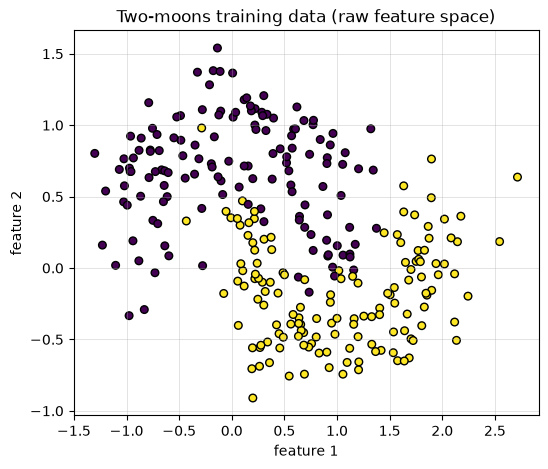

In [17]:
# Generate the two-moons dataset

X, y = make_moons(
    n_samples=400,
    noise=0.25,
    random_state=SEED
)

# Train/validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.3,
    random_state=SEED,
    stratify=y
)

print("Shapes:")
print("  X_train:", X_train.shape, "  X_val:", X_val.shape)

# Quick scatter plot of the raw features
fig, ax = plt.subplots()
scatter = ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolor="k", s=30)
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.set_title("Two-moons training data (raw feature space)")
plt.show()


### Core Task 1 — Linear SVM baseline

We will first fit a **linear SVM** (no kernel trick) on the scaled features:

1. Run the cell below to fit the model and plot the decision boundary.  
2. Note the **training** and **validation** accuracies.  
3. In the markdown cell that follows, briefly describe **where** the linear model struggles.

Feel free to experiment by changing **C** (e.g., `0.1`, `1`, `10`, `100`) and re-running the cell.


Linear SVM train accuracy: 0.875
Linear SVM val   accuracy: 0.850


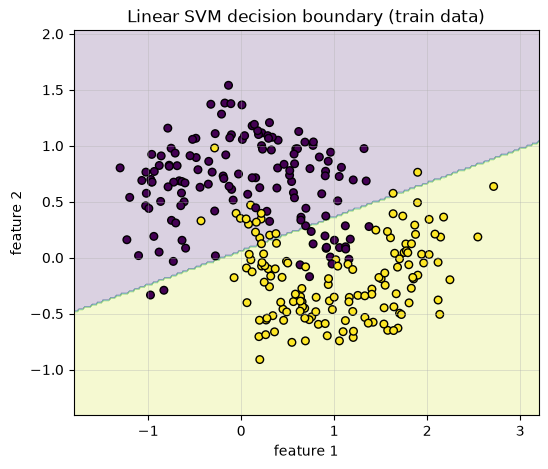

In [18]:
# Linear SVM on scaled features

linear_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=1.0, random_state=SEED))
])

linear_clf.fit(X_train, y_train)

y_train_pred = linear_clf.predict(X_train)
y_val_pred = linear_clf.predict(X_val)

print(f"Linear SVM train accuracy: {accuracy_score(y_train, y_train_pred):.3f}")
print(f"Linear SVM val   accuracy: {accuracy_score(y_val, y_val_pred):.3f}")

fig, ax = plt.subplots()
plot_decision_boundary(linear_clf, X_train, y_train, ax=ax, title="Linear SVM decision boundary (train data)")
plt.show()


**Quick reflection (write a few sentences here):**

- Where does the **linear** decision boundary misclassify points?  
- Does changing **C** make the boundary noticeably more or less curved, or just change the margin?  


### Core Task 2 — RBF-kernel SVM and hyperparameters

Now let's use an **RBF kernel**, which implicitly maps points into a higher-dimensional feature space.

1. Run the cell below with the default `C` and `gamma`.  
2. Compare train/validation accuracy to the linear SVM.  
3. Change `C` and `gamma` to explore:
   - A **clearly underfitting** model (very smooth boundary, low train accuracy).  
   - A **clearly overfitting** model (boundary wiggles a lot, train accuracy ≈ 1.0 but val accuracy drops).  

Record at least two interesting settings in the small results table that is printed.


,C,gamma,train_acc,val_acc
10,10.0,1.0,0.967857,0.916667
15,20.0,1.0,0.964286,0.916667
12,10.0,10.0,0.985714,0.908333
7,5.0,10.0,0.978571,0.908333
2,1.0,10.0,0.964286,0.908333
5,5.0,1.0,0.960714,0.908333
16,20.0,5.0,0.985714,0.900000
6,5.0,5.0,0.975000,0.900000
20,40.0,1.0,0.964286,0.900000
0,1.0,1.0,0.960714,0.900000



Chosen settings:
  Best-ish:   C=10.0, gamma=1.0
  Overfitting: C=40.0, gamma=40.0


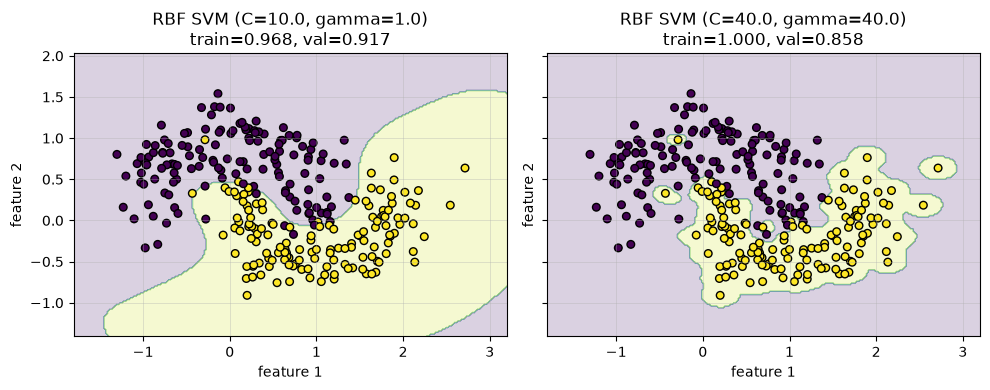

In [19]:
# Small hyperparameter sweep for RBF-kernel SVM on the moons data

C_values = [1.0, 5, 10.0, 20, 40]
gamma_values = [1.0, 5, 10.0, 20, 40]

results = []

for C in C_values:
    for gamma in gamma_values:
        rbf_clf = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(kernel="rbf", C=C, gamma=gamma, random_state=SEED))
        ])
        rbf_clf.fit(X_train, y_train)
        y_train_pred = rbf_clf.predict(X_train)
        y_val_pred = rbf_clf.predict(X_val)
        train_acc = accuracy_score(y_train, y_train_pred)
        val_acc = accuracy_score(y_val, y_val_pred)
        results.append({
            "C": C,
            "gamma": gamma,
            "train_acc": train_acc,
            "val_acc": val_acc
        })

results_df = pd.DataFrame(results).sort_values(by=["val_acc", "train_acc"], ascending=False)
display(results_df)

# Choose one promising and one overfitting setting for visualization
best_row = results_df.iloc[0]
overfit_row = results_df.sort_values(by="train_acc", ascending=False).iloc[0]

print("\nChosen settings:")
print("  Best-ish:   C={C}, gamma={gamma}".format(**best_row.to_dict()))
print("  Overfitting: C={C}, gamma={gamma}".format(**overfit_row.to_dict()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

for row, ax, label in [
    (best_row, axes[0], "Approx. best val accuracy"),
    (overfit_row, axes[1], "Highest train accuracy (likely overfit)"),
]:
    C = row["C"]
    gamma = row["gamma"]
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=C, gamma=gamma, random_state=SEED))
    ])
    clf.fit(X_train, y_train)
    plot_decision_boundary(
        clf,
        X_train,
        y_train,
        ax=ax,
        title=f"RBF SVM (C={C}, gamma={gamma})\ntrain={accuracy_score(y_train, clf.predict(X_train)):.3f}, val={accuracy_score(y_val, clf.predict(X_val)):.3f}"
    )

plt.tight_layout()
plt.show()


**Quick reflection (write a few sentences here):**

- How does **gamma** affect the *smoothness* vs *wiggliness* of the boundary?
**smaller gamma makes boundary more smooth, larger gamma makes boundary more wiggly.**
- How does **C** trade off margin size vs training error?
****
- In your small sweep, which setting(s) seemed like a **reasonable compromise** between under- and overfitting?  


## Part 2 — (Optional stretch) Explicit polynomial features vs kernel SVM

Kernels let us work with very high-dimensional (even infinite-dimensional) feature spaces **implicitly**. To contrast this, we'll build a simple **explicit** polynomial feature map and a logistic regression classifier.

**If you have time:**

1. Run the cell below to fit:
   - Logistic regression on **raw** features.  
   - Logistic regression on **degree-3 polynomial** features.  
2. Compare their performance and decision boundaries to the kernel SVM you just explored.  


raw     — train acc: 0.871, val acc: 0.858
poly-3  — train acc: 0.896, val acc: 0.900


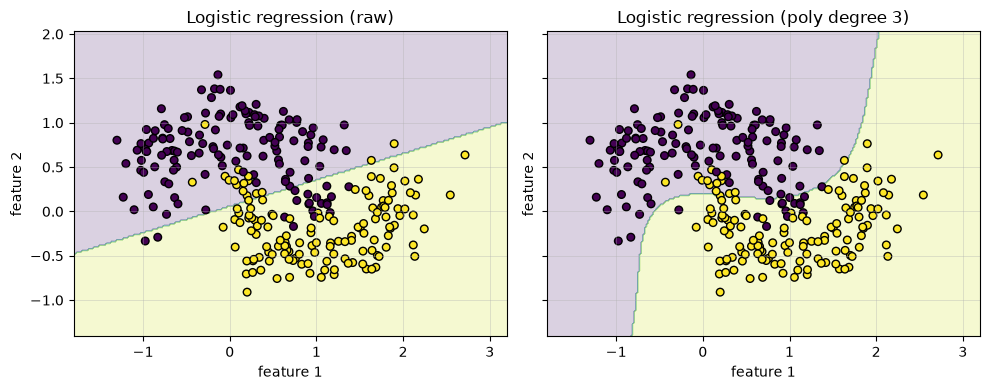

In [20]:
# Logistic regression with and without explicit polynomial features (toy comparison)

# Baseline: logistic regression on raw features
logreg_raw = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=SEED))
])
logreg_raw.fit(X_train, y_train)

# Polynomial features (degree 3) + logistic regression
logreg_poly = Pipeline([
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=2000, random_state=SEED))
])
logreg_poly.fit(X_train, y_train)

for name, model in [("raw", logreg_raw), ("poly-3", logreg_poly)]:
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)
    print(f"{name:7s} — train acc: {accuracy_score(y_train, y_train_pred):.3f}, val acc: {accuracy_score(y_val, y_val_pred):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

plot_decision_boundary(logreg_raw, X_train, y_train, ax=axes[0], title="Logistic regression (raw)")
plot_decision_boundary(logreg_poly, X_train, y_train, ax=axes[1], title="Logistic regression (poly degree 3)")

plt.tight_layout()
plt.show()


## Part 3 — (Optional stretch) Linear vs RBF SVMs on handwritten digits

To connect the toy 2D example with a more realistic dataset, let's briefly compare **linear** and **RBF-kernel** SVMs on the scikit-learn `digits` dataset (8×8 grayscale images of handwritten digits 0–9).

This part is **stretch**: prioritize Parts 1–2 first.

**Goals (if you attempt this):**

- Build a train/validation/test split.  
- Fit a **linear SVM** and an **RBF SVM** inside scaling pipelines.  
- Compare their accuracies and think about when kernel methods are worth the extra cost.  


In [21]:
# Load the digits dataset
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print("Digits shape:", X_digits.shape)
print("Unique labels:", np.unique(y_digits))

# Train/validation/test split (60/20/20)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_digits, y_digits,
    test_size=0.2,
    random_state=SEED,
    stratify=y_digits
)
X_train_d, X_val_d, y_train_d, y_val_d = train_test_split(
    X_temp, y_temp,
    test_size=0.25,  # 0.25 * 0.8 = 0.2 of original -> 60/20/20
    random_state=SEED,
    stratify=y_temp
)

print("Train/val/test sizes:", X_train_d.shape[0], X_val_d.shape[0], X_test.shape[0])

# Linear SVM
linear_digits = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=1.0, random_state=SEED))
])
linear_digits.fit(X_train_d, y_train_d)

# RBF SVM (use a modest C and gamma for speed)
rbf_digits = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=10.0, gamma=0.01, random_state=SEED))
])
rbf_digits.fit(X_train_d, y_train_d)

def evaluate_model(name, model, X_tr, y_tr, X_v, y_v, X_te, y_te):
    y_tr_pred = model.predict(X_tr)
    y_v_pred = model.predict(X_v)
    y_te_pred = model.predict(X_te)
    print(f"{name:10s} — train: {accuracy_score(y_tr, y_tr_pred):.3f}, val: {accuracy_score(y_v, y_v_pred):.3f}, test: {accuracy_score(y_te, y_te_pred):.3f}")

evaluate_model("Linear SVM", linear_digits, X_train_d, y_train_d, X_val_d, y_val_d, X_test, y_test)
evaluate_model("RBF SVM", rbf_digits, X_train_d, y_train_d, X_val_d, y_val_d, X_test, y_test)


Digits shape: (1797, 64)
Unique labels: [0 1 2 3 4 5 6 7 8 9]
Train/val/test sizes: 1077 360 360
Linear SVM — train: 0.997, val: 0.958, test: 0.947
RBF SVM    — train: 1.000, val: 0.978, test: 0.975


**Stretch reflection (if you have time):**

- How big is the **gap** between linear and RBF SVM on the digits data?  
- Given the extra compute cost of RBF kernels (and the need to tune `C` and `gamma`), when might you still prefer a **linear** model?  
- How do these results connect back to the two-moons example and the idea of **feature maps**?  
